<a href="https://colab.research.google.com/github/CBYERDECODE/House_Prices_EDA/blob/main/house_prices%20_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Prices Exploratory Data Analysis Project


### Objective:
Conduct an Exploratory Data Analysis (EDA) of the Ames Housing dataset to understand which factors drive house sale prices, without employing any machine learning algorithms.

### Guiding Questions:
1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does overall quality (`OverallQual`) change price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they errors or real but unusual sales?
6. Which columns have missing values, and which of those are not truly missing?

# 2. Data Loading (Step 1)

We will load the house price dataset (`train.csv`), examine its dimensions, inspect the first few rows, and identify the extent of missing data.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Configure visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load dataset
df = pd.read_csv('/content/train.csv')
print(f"Dataset Shape: {df.shape}")
print("First 5 Rows:")
display(df.head())

# Missing values percentage
missing_counts = df.isnull().sum()
missing_percent = 100 * missing_counts / len(df)
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percentage': missing_percent})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
print("Columns with missing values:")
display(missing_df)

Dataset Shape: (1460, 81)
First 5 Rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Columns with missing values:


,Missing Count,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


# 3. Data Understanding (Steps 2 and 3)

Here, we categorize our features into Numerical, Categorical, and Ordinal groups, map ordinal variables to structured pandas categorical columns, and generate descriptive statistics.

In [4]:
# Step 2: Classify Variables
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

# Map Ordinal variables
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for col in ordinal_map:
    if col in df.columns:
        df[col] = pd.Categorical(df[col], categories=ordinal_map[col], ordered=True)

# Display Descriptive Statistics
print("Numerical Variables Summary:")
display(df[numeric_cols].describe().T)

# Center and Spread calculations
for col in ['SalePrice', 'GrLivArea', 'LotArea']:
    print(f"\n{col} Statistics:")
    print(f"  Mean:   {df[col].mean():.2f}")
    print(f"  Median: {df[col].median():.2f}")
    print(f"  Mode:   {df[col].mode()[0]:.2f}")

Numerical Variables Summary:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



SalePrice Statistics:
  Mean:   180921.20
  Median: 163000.00
  Mode:   140000.00

GrLivArea Statistics:
  Mean:   1515.46
  Median: 1464.00
  Mode:   864.00

LotArea Statistics:
  Mean:   10516.83
  Median: 9478.50
  Mode:   7200.00


# 4. Data Cleaning (Step 9)
We will handle missing values, map appropriate placeholder values, perform logical consistency checks, and verify clean data structure.

In [5]:
# Check duplicate count
dup_count = df.duplicated().sum()
print(f"Number of duplicated rows: {dup_count}")

# Map nulls to 'None' for columns where NA represents absence of feature
none_fill_cols = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType']
for col in none_fill_cols:
    if col in df.columns:
        df[col] = df[col].fillna('None')

# Handle continuous missing values with the median grouped by Neighborhood
if 'LotFrontage' in df.columns:
    df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

# Logical consistency checks
impossible_years = df[df['YearBuilt'] > df['YrSold']]
print(f"Number of houses built after sold: {len(impossible_years)}")

# Check outstanding missing values
remaining_missing = df.isnull().sum().sum()
print(f"Remaining missing values in the dataset: {remaining_missing}")

Number of duplicated rows: 0
Number of houses built after sold: 0
Remaining missing values in the dataset: 2798


# 5. Univariate Analysis (Step 4)
We look closely at the target variable `SalePrice` to determine distribution characteristics and check for skewness.

Skewness of SalePrice: 1.88


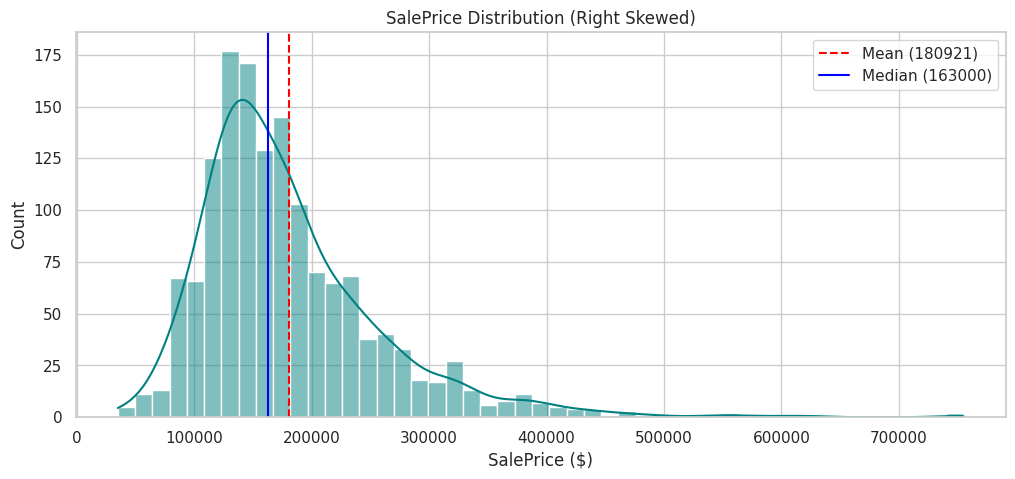

In [6]:
skewness = df['SalePrice'].skew()
print(f"Skewness of SalePrice: {skewness:.2f}")

plt.figure(figsize=(12, 5))
sns.histplot(df['SalePrice'], kde=True, color='teal')
plt.axvline(df['SalePrice'].mean(), color='red', linestyle='--', label=f"Mean ({df['SalePrice'].mean():.0f})")
plt.axvline(df['SalePrice'].median(), color='blue', linestyle='-', label=f"Median ({df['SalePrice'].median():.0f})")
plt.title("SalePrice Distribution (Right Skewed)")
plt.xlabel("SalePrice ($)")
plt.legend()
plt.show()

# 6. Bivariate & Multivariate Analysis (Steps 5, 6, 7)
Here we analyze correlations, view strong drivers of house price, and construct a correlation heatmap of the top 10 features.

Top 10 correlated features with SalePrice:
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
Name: SalePrice, dtype: float64


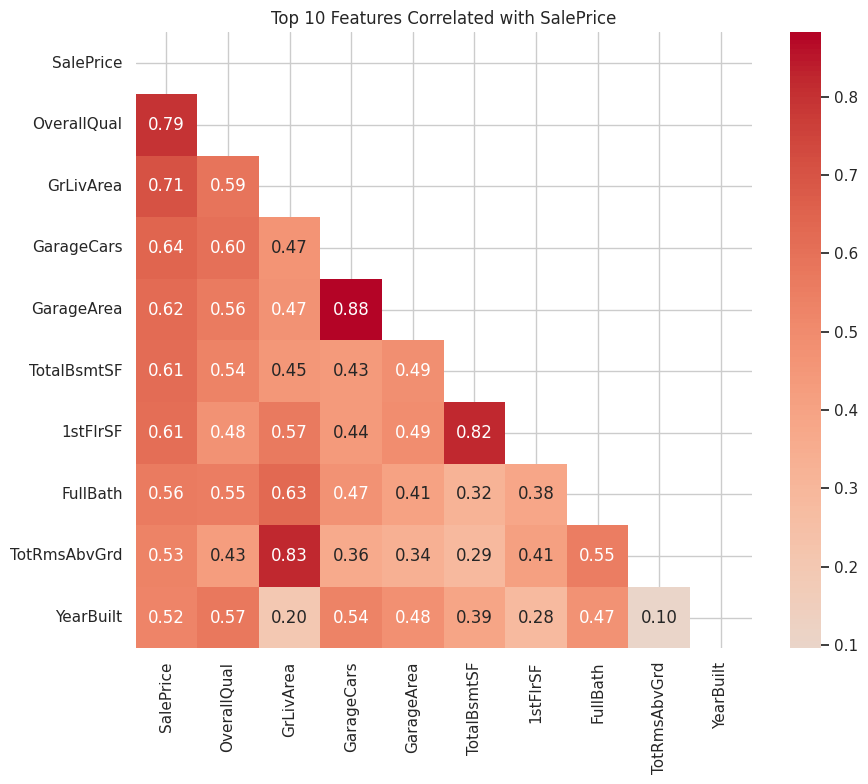

In [7]:
# Correlation with target
correlations = df[numeric_cols].corr()['SalePrice'].sort_values(ascending=False)
top_10_features = correlations.head(10).index.tolist()
print("Top 10 correlated features with SalePrice:")
print(correlations.head(10))

# Correlation Heatmap
corr_top = df[top_10_features].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, fmt=".2f", cmap='coolwarm', center=0, mask=mask, square=True)
plt.title("Top 10 Features Correlated with SalePrice")
plt.show()

# 7. Outlier Analysis (Step 8)
We write custom functions to detect outliers using Interquartile Range (IQR) and standard Z-score methods, then decide whether to clean or keep them.


GrLivArea Outlier Detection:
  IQR method flags:      31 points
  Z-score method flags:  16 points
  Overlapping outlier points: 16

SalePrice Outlier Detection:
  IQR method flags:      61 points
  Z-score method flags:  22 points
  Overlapping outlier points: 22


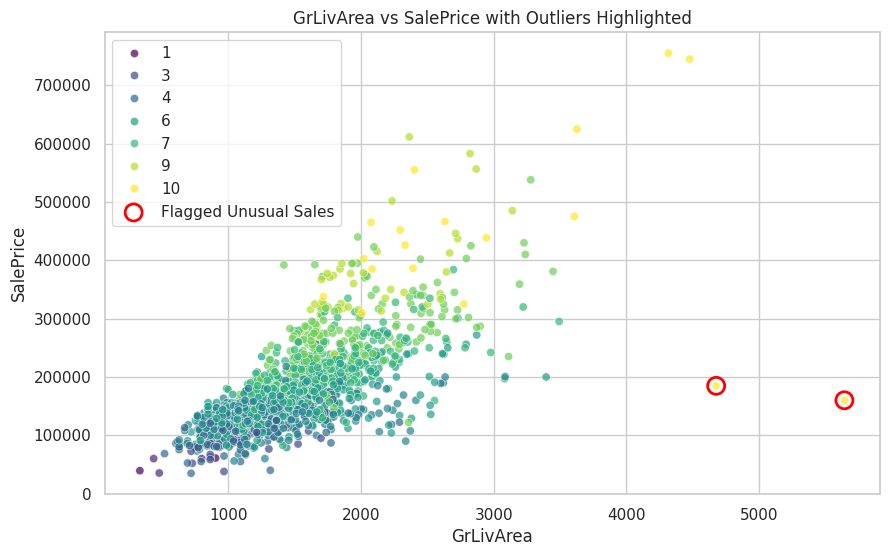

In [8]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[z.abs() > threshold]

for column in ['GrLivArea', 'SalePrice']:
    iqr_outs = iqr_outliers(df[column])
    z_outs = zscore_outliers(df[column])
    overlap = list(set(iqr_outs.index) & set(z_outs.index))
    print(f"\n{column} Outlier Detection:")
    print(f"  IQR method flags:      {len(iqr_outs)} points")
    print(f"  Z-score method flags:  {len(z_outs)} points")
    print(f"  Overlapping outlier points: {len(overlap)}")

# Scatter Plot highlighting outliers
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', hue='OverallQual', palette='viridis', alpha=0.7)
# Highlight very large houses with low price
outliers = df[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)]
plt.scatter(outliers['GrLivArea'], outliers['SalePrice'], color='red', s=150, facecolors='none', edgecolors='red', linewidth=2, label='Flagged Unusual Sales')
plt.title("GrLivArea vs SalePrice with Outliers Highlighted")
plt.legend()
plt.show()

# 8. Final Dashboard (Step 10)
Creating a single comprehensive visual panel representing our core insights from this project.

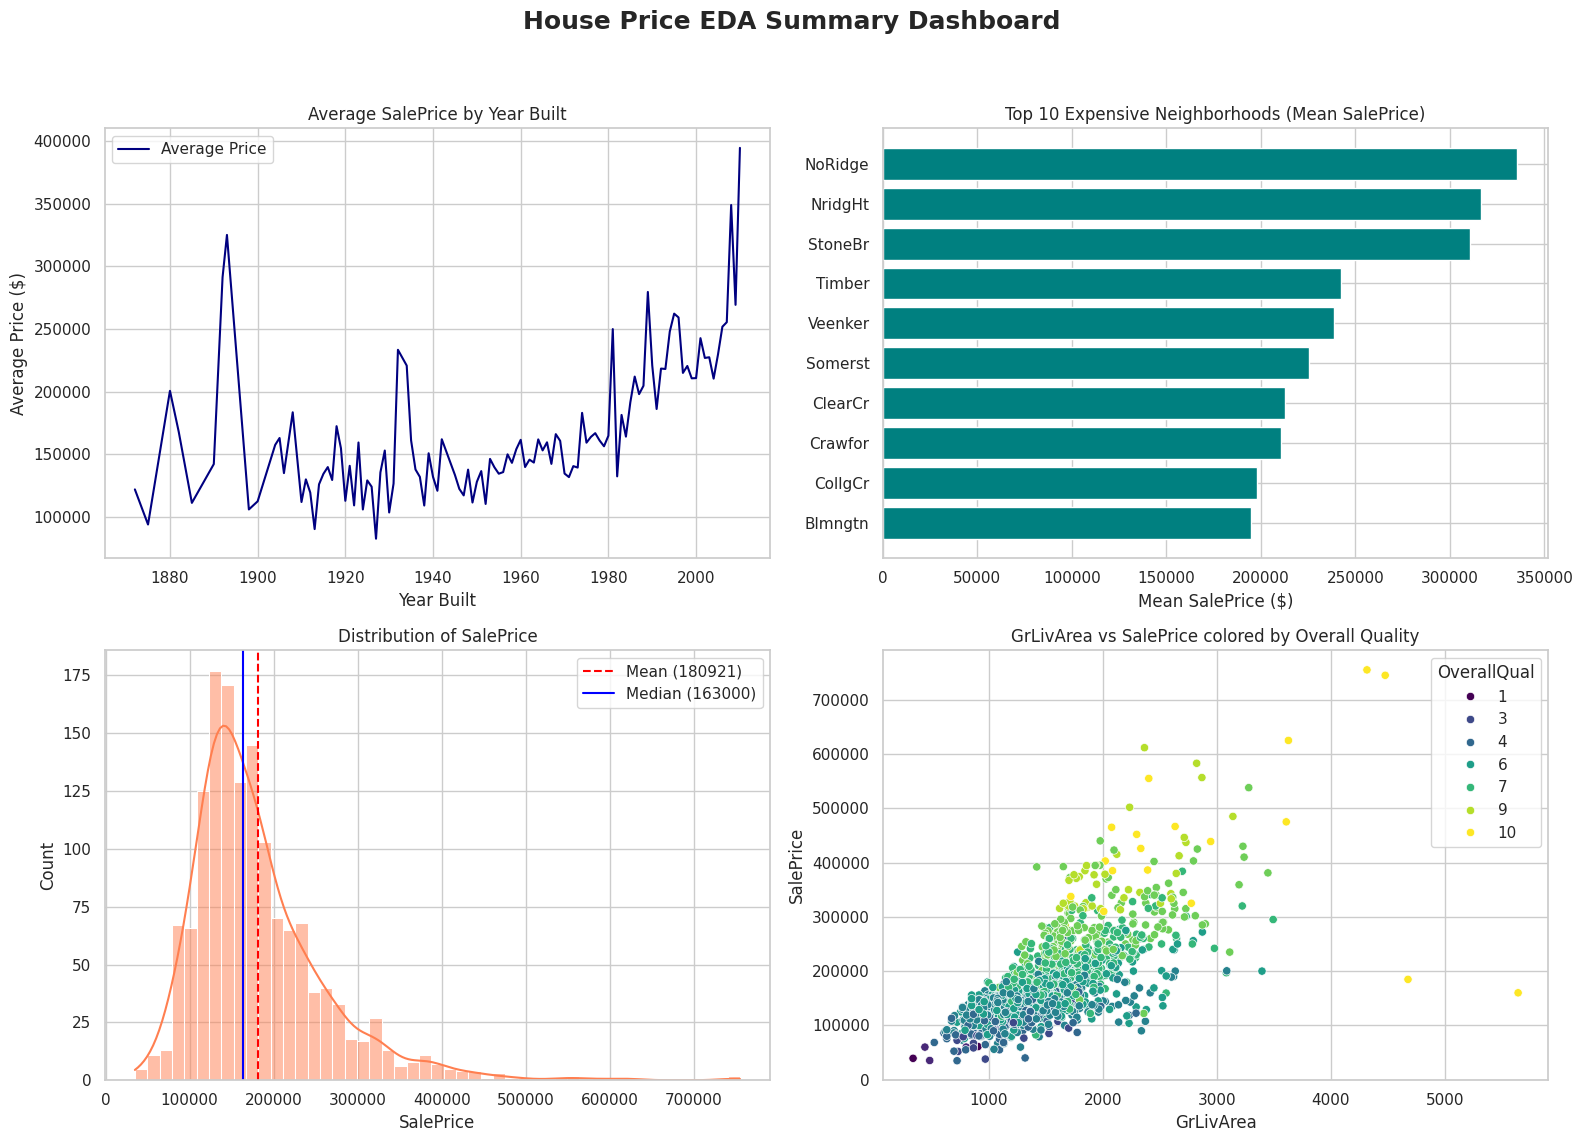

Dashboard saved as 'eda_dashboard.png' successfully!


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("House Price EDA Summary Dashboard", fontsize=18, fontweight='bold')

# Panel 1: Matplotlib Line Plot
year_price = df.groupby('YearBuilt')['SalePrice'].mean()
axes[0, 0].plot(year_price.index, year_price.values, color='navy', label='Average Price')
axes[0, 0].set_title("Average SalePrice by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Price ($)")
axes[0, 0].legend()

# Panel 2: Matplotlib Bar Plot
top_neighborhoods = df.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False).head(10)
axes[0, 1].barh(top_neighborhoods.index, top_neighborhoods.values, color='teal')
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("Top 10 Expensive Neighborhoods (Mean SalePrice)")
axes[0, 1].set_xlabel("Mean SalePrice ($)")

# Panel 3: Seaborn Histplot with KDE
sns.histplot(df['SalePrice'], kde=True, color='coral', ax=axes[1, 0])
axes[1, 0].axvline(df['SalePrice'].mean(), color='red', linestyle='--', label=f'Mean ({df["SalePrice"].mean():.0f})')
axes[1, 0].axvline(df['SalePrice'].median(), color='blue', linestyle='-', label=f'Median ({df["SalePrice"].median():.0f})')
axes[1, 0].set_title("Distribution of SalePrice")
axes[1, 0].legend()

# Panel 4: Seaborn Scatter plot
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', hue='OverallQual', palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title("GrLivArea vs SalePrice colored by Overall Quality")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("eda_dashboard.png")
plt.show()
print("Dashboard saved as 'eda_dashboard.png' successfully!")

Conclusions, Key Insights, and Limitations
What We Learned from This Project
1. SalePrice Distribution: Most houses are sold for less than $200,000
a  few expensive houses increases the avg price to ($180,900), while the middle price is ($163,000)

2. Important Features: Overall Quality (OverallQual) has the strongest relationship with house prices
living Area (GrLivArea) and parking space also affect house prices

3. Neighborhood Price Trends : House prices are different in different neighborhoods  NoRidge and NridgHt have average prices above $300,000, while some other neighborhoods have lower average prices

4. Outliers: Some houses have unusually large living areas but surprisingly low prices. These unusual houses may affect our analysis and should be checked carefully

5. Missing Values: Some columns, such as PoolQC, MiscFeature, and Alley, have many missing values. These values often mean that the house does not have that feature, rather than indicating an error

Project Limitations
- we mainly studied linear relationships between house prices and other features
- we did not study relationships between features such as how quality and neighborhood together affect house prices
- outliers can affect our results and make some statistical calculations less accurate

Final Conclusion

This project helped us understand the factors that affect house prices we found that house quality, living area, and neighborhood are important features
 EDA also helped us identify missing values and unusual data points before building a machine learning model